<a href="https://colab.research.google.com/github/dinarrahman30/ml_midexam/blob/main/20926006_SK5017_MidExam_Part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Classification

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
abalone = fetch_ucirepo(id=1)

# data (as pandas dataframes)
X = abalone.data.features
y = abalone.data.targets

# metadata
print(abalone.metadata)

# variable information
print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

In [ ]:
abalone.data.features.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


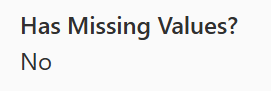

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

# Features are the physical measurements (excluding Sex)
# Target is the 'Sex' column
features_cols = [col for col in abalone.data.features.columns if col != 'Sex']
X = abalone.data.features[features_cols].copy()

# Include 'Rings' as a physical measurement feature
X['Rings'] = abalone.data.targets['Rings']

y = abalone.data.features['Sex']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
models = {
    'SVM': SVC(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Train and evaluate models
for name, model in models.items():
    # Fit the model to the training data
    model.fit(X_train_scaled, y_train.values.ravel())

    # Make predictions on the test data
    y_pred = model.predict(X_test_scaled)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    print(f"=== {name} Performance ===")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f} (Weighted)")
    print(f"Recall:    {recall:.4f} (Weighted)")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 40 + "\n")

=== SVM Performance ===
Accuracy:  0.5526
Precision: 0.5510 (Weighted)
Recall:    0.5526 (Weighted)

Classification Report:
              precision    recall  f1-score   support

           F       0.53      0.22      0.31       261
           I       0.66      0.78      0.72       269
           M       0.47      0.63      0.54       306

    accuracy                           0.55       836
   macro avg       0.55      0.55      0.52       836
weighted avg       0.55      0.55      0.53       836

----------------------------------------

=== Random Forest Performance ===
Accuracy:  0.5395
Precision: 0.5317 (Weighted)
Recall:    0.5395 (Weighted)

Classification Report:
              precision    recall  f1-score   support

           F       0.42      0.37      0.39       261
           I       0.72      0.78      0.75       269
           M       0.46      0.47      0.47       306

    accuracy                           0.54       836
   macro avg       0.53      0.54      0.54    

# Analysis

Berdasarkan pada hasil akhir dari evaluasi performa kedua model machine learning SVM dan Randon Forest, model Support Vector Machine (SVM) memiliki tingkat akurasi lebih tinggi sebesar 0.5526, dibandingkan dengan tingkat akurasi model Random Forest sebesar 0.5395. Selisih keduanya 0.0131.